In [ ]:
import pandas as pd
import numpy as np
a = np.array([1, 1.1, 1.3, 1.6, 2, 2.5, 3.1, 3.8, 4.6, 5.5])

a = pd.DataFrame(a.reshape(-1, 1))

for col in a.columns:
    print(a[col].rolling(window=3, min_periods=1).mean())

In [ ]:
a = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

list = ['a', 'b', 's']

if all(elt in a for elt in list):
    print('yes')
else:
    print('no')

In [19]:
from neuralforecast.models import NBEATS, PatchTST, NBEATSx, NHITS
from neuralforecast.losses.pytorch import HuberLoss
from neuralforecast.core import NeuralForecast
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score

horizon_max = 5

dataframe = pd.DataFrame({
    'ds': [i for i in range(100)],
    'y': [i for i in range(100)],
    'unique_id': ['a' for i in range(100)]
})

# Add 4 NaN rows to the dataframe
nan_rows = pd.DataFrame({
    'ds': [100, 101, 102, 103],
    'y': [0, 0, 0, 0], 
    'unique_id': ['a', 'a', 'a', 'a']
})
dataframe = pd.concat([dataframe, nan_rows], ignore_index=True)


model = NBEATS(h=5,
               input_size=10,
               max_steps=100,
               accelerator='cuda',
               devices=[0],
               logger=False)

nf = NeuralForecast(models=[model], freq=1)

cv_df = nf.cross_validation(dataframe, test_size=28, val_size=10, step_size=1, n_windows=None, verbose=0)

dataframe = dataframe.iloc[:-(horizon_max-1)]

predictions = [[] for i in range(horizon_max)]
r2_scores = [[] for i in range(horizon_max)]

# Sort the values by cutoff date
cv_df = cv_df.sort_values(by=['cutoff', 'ds'])
    
# Group the predicions by horizon
for horizon in range(horizon_max):
    # Get the predictions that are horizon steps ahead from each cutoff date
    horizon_predictions = cv_df.groupby('cutoff').nth(horizon)['NBEATS'].values
    predictions[horizon] = horizon_predictions

# Clean up the results
for i in range(horizon_max):
    if i == 0:
        predictions[i] = predictions[i][-20:]
    else:
        predictions[i] = predictions[i][(horizon_max-i-1):-i]   

# Calculate the r2 scores and store them in a list
for i in range(horizon_max):
    r2_scores[i].append(r2_score(dataframe['y'][-20:], predictions[i]))

Seed set to 1
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name         | Type          | Params | Mode 
-------------------------------------------------------
0 | loss         | MAE           | 0      | train
1 | padder_train | ConstantPad1d | 0      | train
2 | scaler       | TemporalNorm  | 0      | train
3 | blocks       | ModuleList    | 2.4 M  | train
-------------------------------------------------------
2.4 M     Trainable params
165       Non-trainable params
2.4 M     Total params
9.600     Total estimated model params size (MB)
31        Modules in train mode
0         Modules in eval mode


Epoch 99: 100%|██████████| 1/1 [00:00<00:00, 10.44it/s, train_loss_step=0.165, train_loss_epoch=0.165, valid_loss=0.0898]

`Trainer.fit` stopped: `max_steps=100` reached.


Epoch 99: 100%|██████████| 1/1 [00:00<00:00, 10.13it/s, train_loss_step=0.165, train_loss_epoch=0.165, valid_loss=0.0898]


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting DataLoader 0: 100%|██████████| 1/1 [00:00<00:00, 50.12it/s]


In [20]:
r2_scores

[[0.9996010661125183],
 [0.9982746243476868],
 [0.9965932965278625],
 [0.9942014813423157],
 [0.9991399049758911]]

In [21]:
predictions

[array([80.07306 , 81.07678 , 82.08073 , 83.08466 , 84.08845 , 85.09246 ,
        86.09669 , 87.100815, 88.104904, 89.10909 , 90.113495, 91.118355,
        92.12329 , 93.1282  , 94.13302 , 95.137054, 96.140816, 97.144745,
        98.149   , 99.15358 ], dtype=float32),
 array([80.15343 , 81.16222 , 82.17086 , 83.1795  , 84.18814 , 85.19678 ,
        86.20545 , 87.213875, 88.222   , 89.230095, 90.23832 , 91.24678 ,
        92.25525 , 93.26374 , 94.2722  , 95.280685, 96.28962 , 97.29841 ,
        98.30689 , 99.31531 ], dtype=float32),
 array([80.193115, 81.208   , 82.222885, 83.23759 , 84.252266, 85.26696 ,
        86.281334, 87.295784, 88.309944, 89.32345 , 90.33692 , 91.35009 ,
        92.36276 , 93.37606 , 94.3893  , 95.402504, 96.41551 , 97.42795 ,
        98.44015 , 99.452065], dtype=float32),
 array([80.180016, 81.2038  , 82.227905, 83.25217 , 84.276695, 85.30144 ,
        86.32622 , 87.35092 , 88.37636 , 89.40203 , 90.42743 , 91.45276 ,
        92.478   , 93.50305 , 94.52791 , 95.5

In [22]:
cv_df

,unique_id,ds,cutoff,NBEATS,y
0,a,76,75,76.059845,76
1,a,77,75,77.126213,77
2,a,78,75,78.162735,78
3,a,79,75,79.156235,79
4,a,80,75,79.895752,80
...,...,...,...,...,...
115,a,99,98,99.153580,99
116,a,100,98,100.324135,0
117,a,101,98,101.475609,0
118,a,102,98,102.722519,0


In [24]:
forecasts = pd.read_csv('../scripts/tests/forecasts.csv')
forecasts.head()

,unique_id,ds,cutoff,NHITS,y
0,85064,2016-12-28,2016-12-27,-0.019981,-0.01
1,85064,2016-12-29,2016-12-27,-0.020080,-0.02
2,85064,2016-12-30,2016-12-27,-0.020364,-0.02
3,85064,2016-12-31,2016-12-27,-0.019902,-0.01
4,85064,2017-01-01,2016-12-27,-0.019659,-0.02


In [1]:
import pandas as pd
import joblib

aquifer_by_stations = joblib.load('../data/interim/ground-water-and-weather-with-forecasts-and-additional-features.joblib')

In [3]:
aquifer_by_stations[85065].columns

Index(['date', 'station_id', 'altitude', 'altitude_diff', 'id', 'location_id',
       'day_time', 'precipitation', 'snow_accumulation', 'temperature_avg',
       ...
       'dd_decodeText_5_ENE', 'dd_decodeText_5_N', 'dd_decodeText_5_NE',
       'dd_decodeText_5_NNW', 'dd_decodeText_5_NW', 'dd_decodeText_5_S',
       'dd_decodeText_5_SE', 'dd_decodeText_5_SW', 'dd_decodeText_5_W',
       'dd_decodeText_5_nil'],
      dtype='object', length=2116)

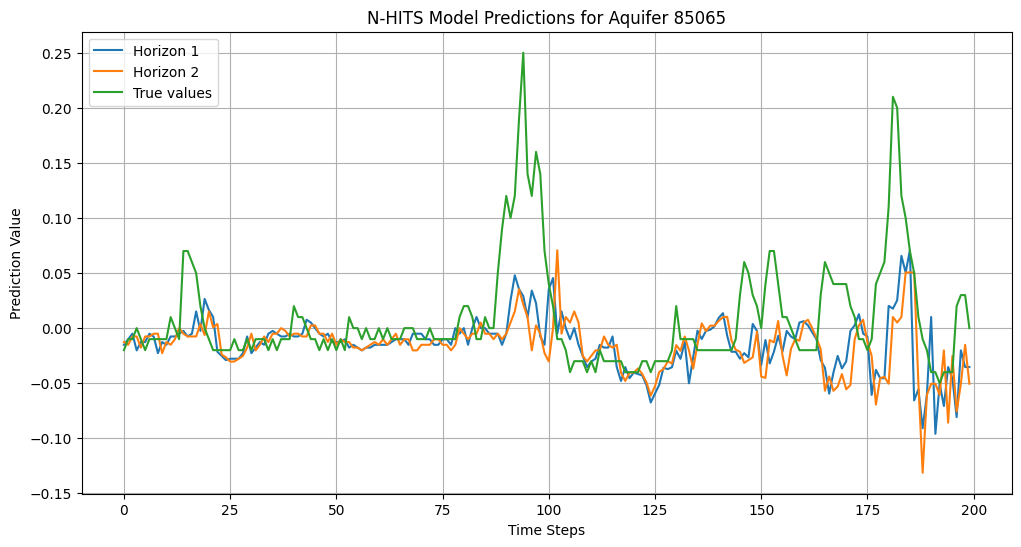

In [15]:
import json
import matplotlib.pyplot as plt

with open('../scripts/results/foundation_models/time_moe_3.json', 'r') as file:
    predictions = json.load(file)

predictions = predictions['predictions']['85065']

aquifer = joblib.load('../data\processed\ground-water-and-weather-with-forecasts.joblib')


# Create figure and axis
plt.figure(figsize=(12, 6))

# Plot each prediction sequence
for i, pred_sequence in enumerate(predictions[2:4]):
    plt.plot(pred_sequence[-200:], label=f'Horizon {i+1}')

plt.plot(aquifer[85065]['altitude_diff'][-200:].reset_index(drop=True), label='True values')

plt.title('N-HITS Model Predictions for Aquifer 85065')
plt.xlabel('Time Steps') 
plt.ylabel('Prediction Value')
plt.legend()
plt.grid(True)
plt.show()
